# Mean MODIS NIR and Sentinel-1 and Sentinel-2 SCF extraction example

This notebook show an example how to extract a MODIS NIR mean time series inside a glaicier outline and Sentinel-1 and Sentinel-2 glacier snow cover fractions. Run the cells in order after installing the dependencies in `README.md`. Google Earth Engine access is required.

In [1]:
import ee
import geemap
from datetime import date, timedelta

import matplotlib.pyplot as plt

# Authenticate once on this machine if needed:
# ee.Authenticate()
ee.Initialize(project="ee-mcallegari")

from glacier_scaf import MODIS_meanNIR, SCAF_S1, SCAF_S2

## 1) Input selection

### Glacier and period selection

In this example Zulmat glacier (RGI id: RGI60-13.14451) is used. Change the ID or supply another EE geometry for a different glacier.

In [2]:
start_date = "2018-06-01"
end_date = "2018-10-01"
# glacier = ee.FeatureCollection("users/josiaszeller/RGVI_v6").filter(ee.Filter.eq('RGIId', 'RGI60-13.14451')).first() \
#     .set('Name', 'Zulmart')
# glacier = ee.FeatureCollection("users/josiaszeller/RGVI_v6").filter(ee.Filter.eq('RGIId', 'RGI60-13.07064')).first() \
#     .set('Name', 'n354')
# glacier = ee.FeatureCollection("users/josiaszeller/RGVI_v6").filter(ee.Filter.eq('RGIId', 'RGI60-13.11609')).first() \
#     .set('Name', 'Golubin')
glacier = ee.FeatureCollection("users/josiaszeller/RGVI_v6").filter(ee.Filter.eq('RGIId', 'RGI60-13.18096')).first() \
    .set('Name', 'Abramov')
glacier_outline = glacier.geometry()

Map = geemap.Map()
Map.centerObject(glacier_outline, 12)
Map.addLayer(glacier_outline, {'color': 'red'}, 'glacier outline', True, 0.6);
Map

Map(center=[39.61452547955412, 71.55122000080574], controls=(WidgetControl(options=['position', 'transparent_b…

### Set the Sentinel SCAF parameters

In [3]:
S2_tile = "42SYJ" # Abramov: 42SYJ, Golubin: 43TDH, no.354: 44TKM, Zulmart = '43SCD'
s2_th_min = 4000 # Abramov: 4000, Golubin: 4000, no.354: 3500, Zulmart = 4000
s2_th_max = 5500 # Abramov: 5500, Golubin: 5800, no.354: 5000, Zulmart = 5500
s2_th_fixed = 5000 # Abramov: 5000, Golubin: 5400, no.354: 4500, Zulmart = 4500

S1_orbit = "ASCENDING"

## MODIS mean NIR time series

In [4]:
modis_nir = MODIS_meanNIR(glacier_outline, start_date, end_date)

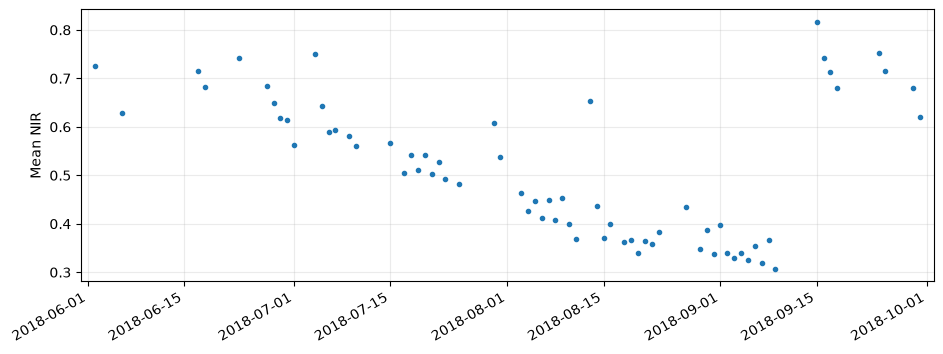

In [5]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(modis_nir.index, modis_nir.values, marker=".", linestyle="")
ax.set(ylabel="Mean NIR")
ax.grid(alpha=0.25)
ax.set_xlim(
    date.fromisoformat(start_date) - timedelta(days=1),
    date.fromisoformat(end_date) + timedelta(days=1),
)
fig.autofmt_xdate()
plt.show()

## Sentinel-1 and Sentinel-2 snow cover fraction time series

In [6]:
s1_scaf = SCAF_S1(start_date, end_date, glacier_outline, S1_orbit)

In [7]:
s2_scaf = SCAF_S2(start_date, end_date, glacier_outline, th_min=s2_th_min, th_max=s2_th_max, th_fixed=s2_th_fixed, tile=S2_tile)

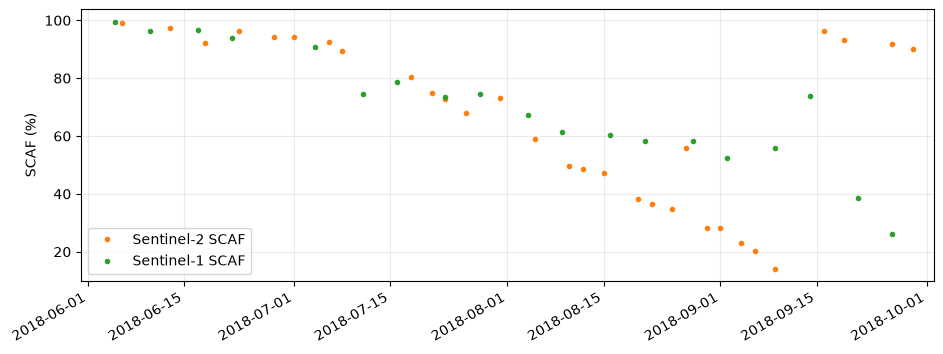

In [8]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(s2_scaf.index, s2_scaf.values, marker=".", linestyle="", label="Sentinel-2 SCAF", color='C1')
ax.plot(s1_scaf.index, s1_scaf.values, marker=".", linestyle="", label="Sentinel-1 SCAF", color='C2')
ax.set(ylabel="SCAF (%)")
ax.grid(alpha=0.25)
ax.legend()
ax.set_xlim(
    date.fromisoformat(start_date) - timedelta(days=1),
    date.fromisoformat(end_date) + timedelta(days=1),
)
fig.autofmt_xdate()
plt.show()

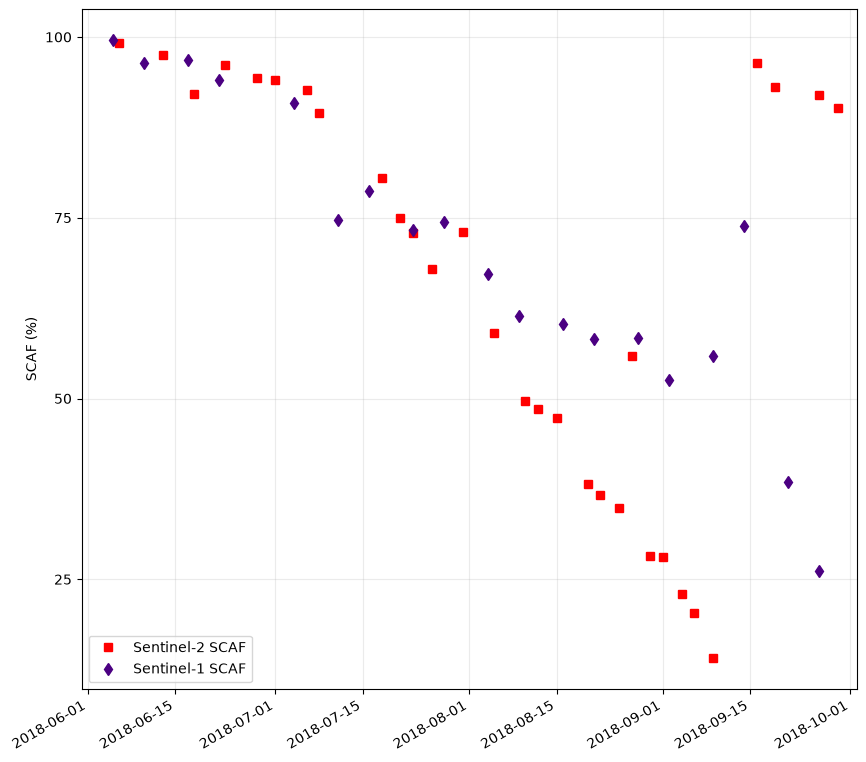

In [9]:
from matplotlib.ticker import MultipleLocator

fig, ax = plt.subplots(figsize=(10,10))
ax.plot(s2_scaf.index, s2_scaf.values, marker="s", linestyle="", label="Sentinel-2 SCAF", color='red')
ax.plot(s1_scaf.index, s1_scaf.values, marker="d", linestyle="", label="Sentinel-1 SCAF", color='indigo')
ax.set(ylabel="SCAF (%)")
ax.yaxis.set_major_locator(MultipleLocator(25))
ax.grid(alpha=0.25)
ax.legend()
ax.set_xlim(
    date.fromisoformat(start_date) - timedelta(days=1),
    date.fromisoformat(end_date) + timedelta(days=1),
)
fig.autofmt_xdate()
plt.show()

In [10]:
s2_scaf

2018-06-06    99.202147
2018-06-13    97.449358
2018-06-18    92.111832
2018-06-23    96.149541
2018-06-28    94.293439
2018-07-01    94.094067
2018-07-06    92.640015
2018-07-08    89.446076
2018-07-18    80.456865
2018-07-21    75.009413
2018-07-23    72.925655
2018-07-26    67.955097
2018-07-31    72.984658
2018-08-05    59.022914
2018-08-10    49.652133
2018-08-12    48.597925
2018-08-15    47.311332
2018-08-20    38.153467
2018-08-22    36.662130
2018-08-25    34.861588
2018-08-27    55.923657
2018-08-30    28.271676
2018-09-01    28.116293
2018-09-04    22.967761
2018-09-06    20.321566
2018-09-09    14.066526
2018-09-16    96.449838
2018-09-19    93.054002
2018-09-26    91.925271
2018-09-29    90.149294
Name: scaf_S2, dtype: float64